In [1]:
#Câu 1
print("Phạm Đức Anh - 6451071001")

import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from matplotlib import style

with open('titanic.csv') as f:
    df = pd.read_csv(f, dtype={'age': np.float64, 'sibsp': np.int64, 'parch': np.int64})

df.head(12)

Phạm Đức Anh - 6451071001


,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1,0,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
5,1,1,"Anderson, Mr. Harry",male,48.0000,0,0,19952,26.5500,E12,S,3,NaN,"New York, NY"
6,1,1,"Andrews, Miss. Kornelia Theodosia",female,63.0000,1,0,13502,77.9583,D7,S,10,NaN,"Hudson, NY"
7,1,0,"Andrews, Mr. Thomas Jr",male,39.0000,0,0,112050,0.0000,A36,S,NaN,NaN,"Belfast, NI"
8,1,1,"Appleton, Mrs. Edward Dale (Charlotte Lamson)",female,53.0000,2,0,11769,51.4792,C101,S,D,NaN,"Bayside, Queens, NY"
9,1,0,"Artagaveytia, Mr. Ramon",male,71.0000,0,0,PC 17609,49.5042,NaN,C,NaN,22.0,"Montevideo, Uruguay"


In [2]:
#Câu 2
print("Phạm Đức Anh - 6451071001")

total = df.isnull().sum().sort_values(ascending=False)
percent_1 = df.isnull().sum() / df.isnull().count() * 100
percent_2 = (round(percent_1, 1)).sort_values(ascending=False)
missing_data = pd.concat([total, percent_2], axis=1, keys=['Total', '%'])
missing_data.head(5)

Phạm Đức Anh - 6451071001


,Total,%
body,1188,90.8
cabin,1014,77.5
boat,823,62.9
home.dest,564,43.1
age,263,20.1


Phạm Đức Anh - 6451071001


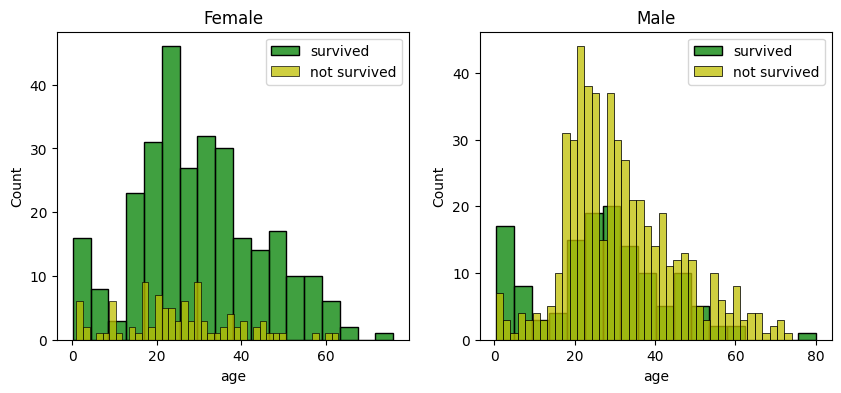

In [3]:
#Câu 3
print("Phạm Đức Anh - 6451071001")

survived = 'survived'
not_survived = 'not survived'
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

women = df[df['sex'] == 'female']
men = df[df['sex'] == 'male']

# Biểu đồ cho Nữ
ax = sns.histplot(women[women['survived']==1].age.dropna(), bins=18, label=survived, ax=axes[0], kde=False, color='g')
ax = sns.histplot(women[women['survived']==0].age.dropna(), bins=40, label=not_survived, ax=axes[0], kde=False, color='y')
ax.legend()
ax.set_title('Female')

# Biểu đồ cho Nam
ax = sns.histplot(men[men['survived']==1].age.dropna(), bins=18, label=survived, ax=axes[1], kde=False, color='g')
ax = sns.histplot(men[men['survived']==0].age.dropna(), bins=40, label=not_survived, ax=axes[1], kde=False, color='y')
ax.legend()
_ = ax.set_title('Male')

Phạm Đức Anh - 6451071001


/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:854: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:#1f77b4'` for the same effect.

  func(*plot_args, **plot_kwargs)
/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:854: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:#1f77b4'` for the same effect.

  func(*plot_args, **plot_kwargs)
/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:854: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:#1f77b4'` for the same effect.

  func(*plot_args, **plot_kwargs)


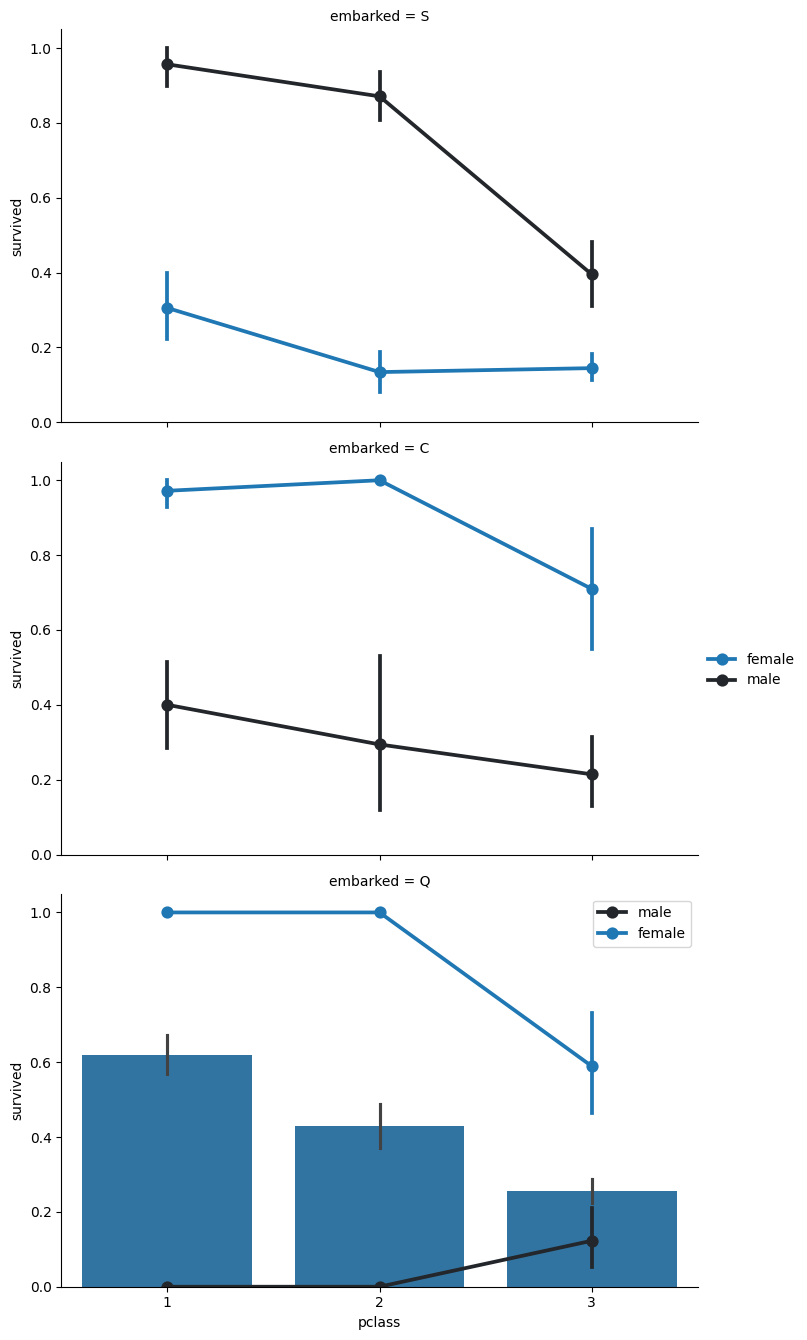

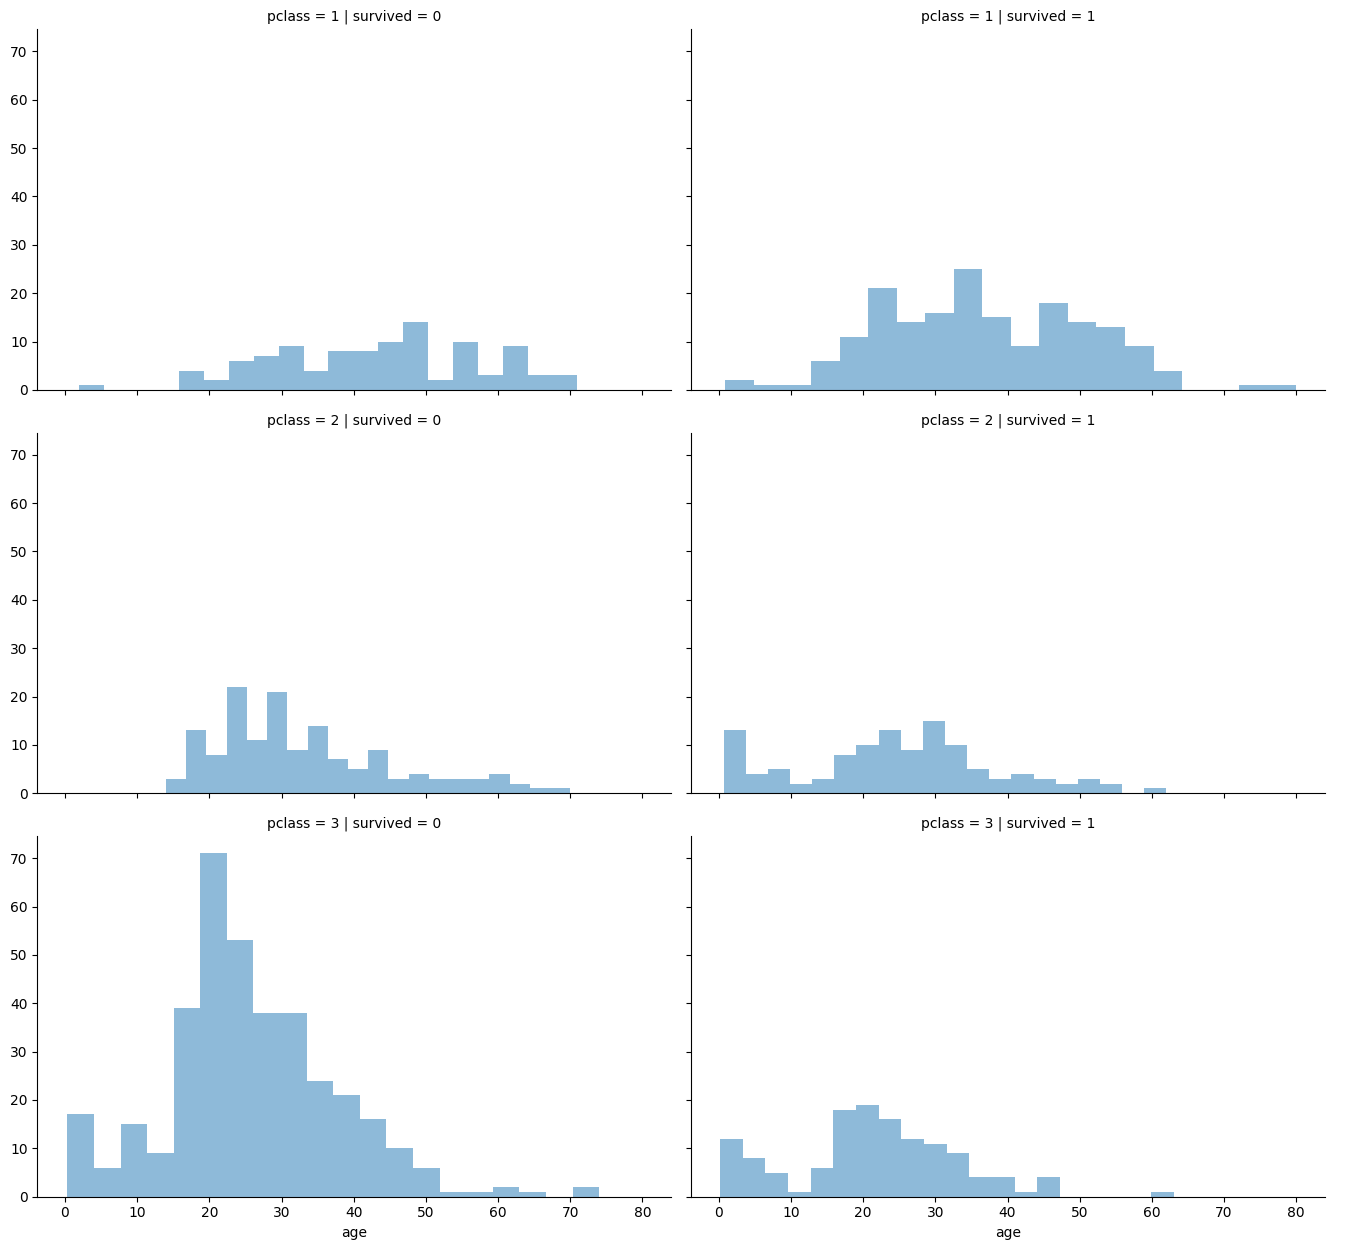

In [4]:
#Câu 4
print("Phạm Đức Anh - 6451071001")

# 1. Tương quan giữa Cổng lên tàu, Loại vé, Giới tính và Khả năng sống sót
FacetGrid = sns.FacetGrid(df, row='embarked', height=4.5, aspect=1.6)
FacetGrid.map(sns.pointplot, 'pclass', 'survived', 'sex', palette=None, order=None, hue_order=None)
FacetGrid.add_legend()

# 2. Tỷ lệ sống sót trung bình theo từng Loại vé (pclass)
sns.barplot(x='pclass', y='survived', data=df)

# 3. Phân bố độ tuổi sống sót/không sống sót theo từng Loại vé
grid = sns.FacetGrid(df, col='survived', row='pclass', height=4.2, aspect=1.6)
grid.map(plt.hist, 'age', alpha=.5, bins=20)
grid.add_legend()

Phạm Đức Anh - 6451071001
not_alone
1    790
0    519
Name: count, dtype: int64


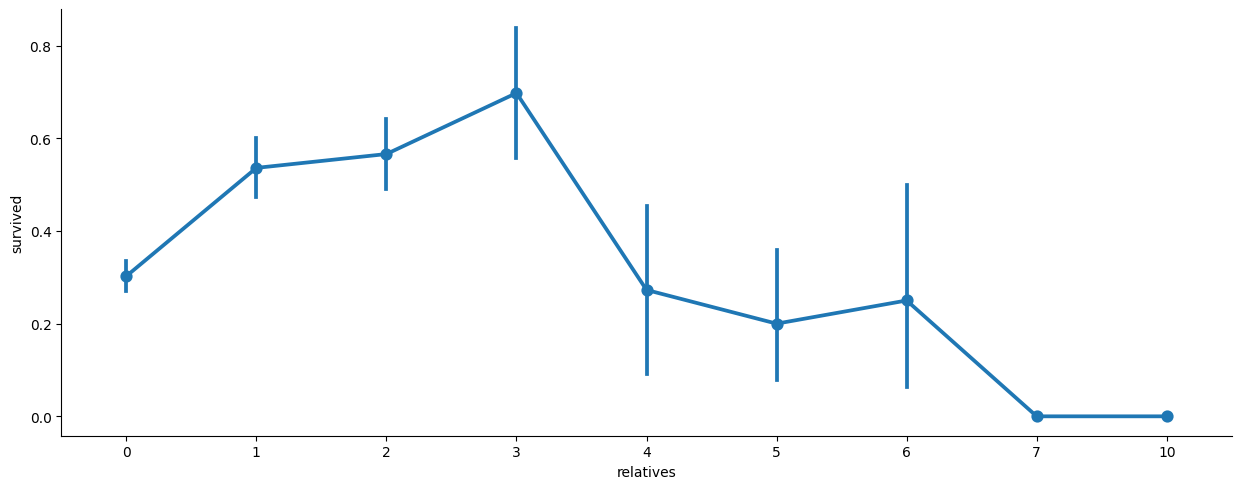

In [5]:
#Câu 5
print("Phạm Đức Anh - 6451071001")

for dataset in [df]:
    dataset['relatives'] = dataset['sibsp'] + dataset['parch']
    dataset.loc[dataset['relatives'] > 0, 'not_alone'] = 0
    dataset.loc[dataset['relatives'] == 0, 'not_alone'] = 1
    dataset['not_alone'] = dataset['not_alone'].astype(int)

print(df['not_alone'].value_counts())

# Vẽ biểu đồ mối quan hệ giữa số người đi cùng và khả năng sống sót
axes = sns.catplot(x='relatives', y='survived', data=df, aspect=2.5, kind='point')

Phạm Đức Anh - 6451071001
--- Thống kê ticket ---
count         1309
unique         929
top       CA. 2343
freq            11
Name: ticket, dtype: object

Số giá trị thiếu của age sau khi xử lý: 0

--- Thống kê embarked ---
count     1307
unique       3
top          S
freq       914
Name: embarked, dtype: object

--- Kiểm tra tổng giá trị thiếu sau tiền xử lý ---
pclass      0
survived    0
name        0
sex         0
age         0
sibsp       0
parch       0
fare        1
embarked    0
deck        0
dtype: int64


/tmp/ipykernel_1366/1921027610.py:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='deck', data=df, ax=axes[0], palette='viridis')


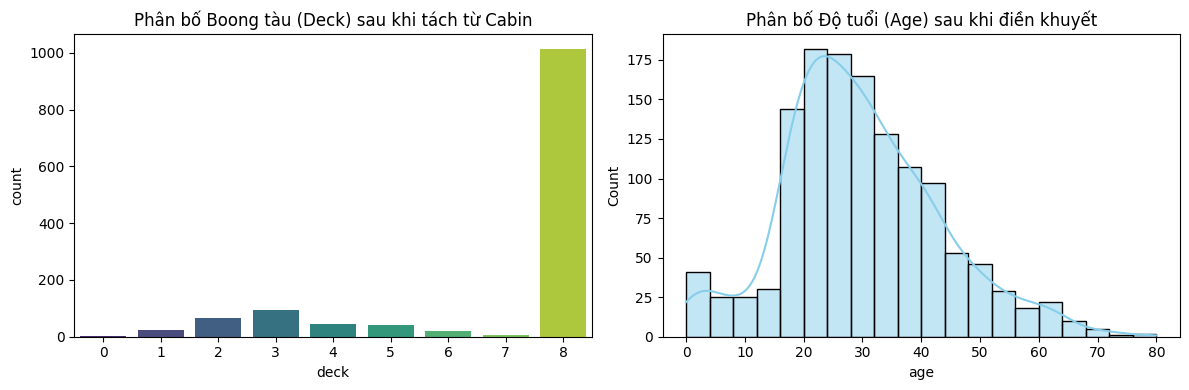

,pclass,survived,name,sex,age,sibsp,parch,fare,embarked,deck
0,1,1,"Allen, Miss. Elisabeth Walton",female,29,0,0,211.3375,S,2
1,1,1,"Allison, Master. Hudson Trevor",male,0,1,2,151.5500,S,3
2,1,0,"Allison, Miss. Helen Loraine",female,2,1,2,151.5500,S,3
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30,1,2,151.5500,S,3
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25,1,2,151.5500,S,3


In [9]:
#Câu 6
print("Phạm Đức Anh - 6451071001")

# Đọc lại dữ liệu gốc để đảm bảo các cột chưa bị xóa khi chạy lại cell
with open('titanic.csv') as f:
    df = pd.read_csv(f, dtype={'age': np.float64, 'sibsp': np.int64, 'parch': np.int64})

import re
deck = {"A": 1, "B": 2, "C": 3, "D": 4, "E": 5, "F": 6, "G": 7, "U": 8}

for dataset in [df]:
    dataset['cabin'] = dataset['cabin'].fillna("U0")
    dataset['deck'] = dataset['cabin'].map(lambda x: re.compile("([a-zA-Z]+)").search(x).group())
    dataset['deck'] = dataset['deck'].map(deck)
    dataset['deck'] = dataset['deck'].fillna(0)
    dataset['deck'] = dataset['deck'].astype(int)

# Xóa thuộc tính cabin
df = df.drop(['cabin'], axis=1)

print("--- Thống kê ticket ---")
print(df['ticket'].describe())

df = df.drop(['ticket'], axis=1)
df = df.drop(['boat'], axis=1)
df = df.drop(['body'], axis=1)
df = df.drop(['home.dest'], axis=1)

for dataset in [df]:
    mean = df["age"].mean()
    std = df["age"].std()
    is_null = dataset["age"].isnull().sum()

    # Sinh số ngẫu nhiên
    rand_age = np.random.randint(mean - std, mean + std, size=is_null)

    # Điền vào các vị trí NaN
    age_slice = dataset["age"].copy()
    age_slice[np.isnan(age_slice)] = rand_age
    dataset["age"] = age_slice
    dataset["age"] = df["age"].astype(int)

print("\nSố giá trị thiếu của age sau khi xử lý:", df["age"].isnull().sum())

print("\n--- Thống kê embarked ---")
print(df['embarked'].describe())

common_value = 'S'
for dataset in [df]:
    dataset['embarked'] = dataset['embarked'].fillna(common_value)

# Hiển thị kết quả trực quan để chụp báo cáo
print("\n--- Kiểm tra tổng giá trị thiếu sau tiền xử lý ---")
print(df.isnull().sum())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x='deck', data=df, ax=axes[0], palette='viridis')
axes[0].set_title('Phân bố Boong tàu (Deck) sau khi tách từ Cabin')

sns.histplot(df['age'], bins=20, kde=True, ax=axes[1], color='skyblue')
axes[1].set_title('Phân bố Độ tuổi (Age) sau khi điền khuyết')
plt.tight_layout()
plt.show()

df.head()